# LATIHAN CLUSTERING MENGGUNAKAN K-MEANS

# Langkah 1: Siapkan library yang diperlukan
dalam latihan ini , model Kmeans, metric evaluasi, pengolah data numerik (numpy), pandas untuk olah data frame, matplotlib dan scaler untuk normalisasi data

In [1]:
from sklearn.cluster import KMeans
from sklearn import metrics
from scipy.spatial.distance import cdist
import numpy as np
import pandas as pd
from mpl_toolkits import mplot3d
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Langkah 2: Load data nasabah
path data sumber harus disesuaikan dengan letak data Anda 

In [2]:
#ambil data
data= pd.read_excel('nasabah.xls')
print(data)

  Nama  Gaji (juta)  Nilai asset (x 100 Juta)  Jumlah kendaraan
0    A            4                         1                 3
1    B            3                         4                 3
2    C            2                         5                 3
3    D            3                         1                 3
4    E            4                         4                 2
5    F            3                         1                 2
6    G            2                         4                 1
7    H            2                         2                 1
8    I            1                         2                 1


Bagian data : 
[[4 1 3]
 [3 4 3]
 [2 5 3]
 [3 1 3]
 [4 4 2]
 [3 1 2]
 [2 4 1]
 [2 2 1]
 [1 2 1]]


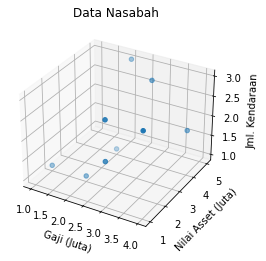

In [3]:
# MENAMPILKAN DATA SECARA VISUAL DALAM VECTOR SPACE

#Ambil bagian data dari dataset
X = np.array(data.iloc[:, 1:4])  #mengambil semua baris, khusus mulai kolom ke-1 dari 4 kolom
print("Bagian data : ")
print(X)

#Membuat grafik data
# 1. Memindah tiap kolom data ke variabel grafik
x1 = np.array(data.iloc[:, 1])
x2 = np.array(data.iloc[:, 2])
x3 = np.array(data.iloc[:, 3])


#2. menyiapkan grafik data
ax = plt.axes(projection ='3d')
#ax adalah objek 3d yang akan ditaruh di grafik data

# 3. Mendefining axes
ax.set_xlabel('Gaji (Juta)')
ax.set_ylabel('Nilai Asset (Juta)')
ax.set_zlabel('Jml. Kendaraan')
ax.scatter(x1, x2, x3)
#data x,y, dan z ditempelkan di objek ax

# 4. Menampilkan grafik
plt.title('Data Nasabah')
plt.show()

# Langkah 3: Menentukan K, dalam contoh ini menggunakan metode Elbow.
Anda dapat menggunakan metode- metode yang lain selain Elbow. Dalam kajian machine learning, biasanya para peneliti menggunakan metode optimasi seperti PSO, Genetika, dll.

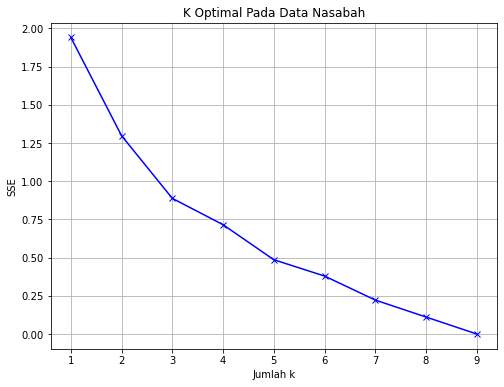

In [5]:
# Menentukan jumlah k terbaik
distortions = []
K = range(1, 10)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=0)
    kmeanModel.fit(X)
    # Hitung SSE (Sum of Squared Errors)
    distortions.append(sum(np.min(cdist(X, kmeanModel.cluster_centers_, 'euclidean'), axis=1)) / X.shape[0])

# Menggambar elbow
plt.figure(figsize=(8, 6))
plt.plot(K, distortions, 'bx-')
plt.xlabel('Jumlah k')
plt.ylabel('SSE')
plt.title('K Optimal Pada Data Nasabah')
plt.xticks(K)  # Menampilkan setiap nilai k di sumbu x
plt.grid(True)
plt.show()

<H4>Bagaimana membaca Pada Grafik K Optimal diatas?</H4>
<br>Perhatikan pada garis distorsi, bagian garis yang membelok sehingga terlihat seperi siku lengan itulah yang disebut ELbow.
<br>Pada gambar tersebut diatas, Elbow terlihat samar pada K=2, K=3).
<br>Dengan demikian, jumlah k=2 dan k=3 bisa digunakan sebagai inisial K pada clustering K-Means.

# Langkah 4: Preprocessing sederhana

In [8]:
# Preprocessing: Normalisasi data dengan Min Max Scaler
scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(X)

In [9]:
x_scaled

array([[1.        , 0.        , 1.        ],
       [0.66666667, 0.75      , 1.        ],
       [0.33333333, 1.        , 1.        ],
       [0.66666667, 0.        , 1.        ],
       [1.        , 0.75      , 0.5       ],
       [0.66666667, 0.        , 0.5       ],
       [0.33333333, 0.75      , 0.        ],
       [0.33333333, 0.25      , 0.        ],
       [0.        , 0.25      , 0.        ]])

# Langkah 5: Clustering dengan model K-means dari skelearn
Dalam hal ini , Anda dapat membuat sendiri fungsi K-Means

In [10]:
# Membuat model K-means
model = KMeans(n_clusters=3, random_state=42).fit(x_scaled)
# Menampilkan Pusat cluetering
print(model.cluster_centers_)

[[7.77777778e-01 5.55111512e-17 8.33333333e-01]
 [2.22222222e-01 4.16666667e-01 0.00000000e+00]
 [6.66666667e-01 8.33333333e-01 8.33333333e-01]]


In [11]:
#Memberi label klaster
data['klaster'] = model.labels_
data

,Nama,Gaji (juta),Nilai asset (x 100 Juta),Jumlah kendaraan,klaster
0,A,4,1,3,0
1,B,3,4,3,2
2,C,2,5,3,2
3,D,3,1,3,0
4,E,4,4,2,2
5,F,3,1,2,0
6,G,2,4,1,1
7,H,2,2,1,1
8,I,1,2,1,1


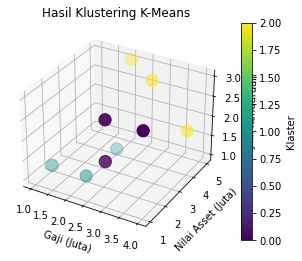

In [12]:
#Menampilkan visual cluster
# 1. Memindah tiap kolom data ke variabel grafik
x1 = np.array(data.iloc[:, 1])
x2 = np.array(data.iloc[:, 2])
x3 = np.array(data.iloc[:, 3])
klaster = np.array(data.iloc[:,4])
ax = plt.axes(projection ='3d')
sc=ax.scatter(x1, x2, x3,  s=150,  c = klaster, marker = 'o', cmap='viridis')
ax.set_xlabel('Gaji (Juta)')
ax.set_ylabel('Nilai Asset (Juta)')
ax.set_zlabel('Jml. Kendaraan')
cbar = plt.colorbar(sc)
cbar.set_label("Klaster")
plt.title('Hasil Klustering K-Means')
plt.show()


# Langkah 6: Analisis Hasil Cluster dengan metode  SILHOUTTE

In [18]:
# import library untuk metode silhoute. Jika Anda belum menginstal yellowbrick, maka akan eror. Maka instalah yellowbrisk
# dengan sintak pip install yellowbrick

In [17]:
pip install yellowbrick

     |████████████████████████████████| 282 kB 1.9 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [19]:
from yellowbrick.cluster import SilhouetteVisualizer

SilhouetteVisualizer(ax=<AxesSubplot:>, colors='yellowbrick',
                     estimator=KMeans(n_clusters=3, random_state=42))

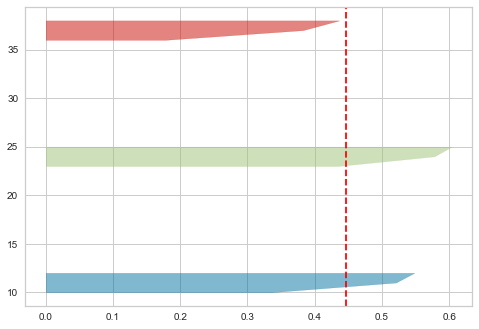

In [20]:
#lakukan clustering dg K-Means, dalam contoh ini menggunakan jumlah klaster 3,  n= 3 ( ini hasil Elbow tadi)
kmmodel = KMeans(n_clusters=3, random_state=42)
visualizer = SilhouetteVisualizer(kmmodel, colors='yellowbrick')
visualizer.fit(x_scaled)

## Analisis Hasil

Anda bisa melihat grafik silhoute diatas. Jika Grafik makin panjang dan nilainya makin tinggi artinya cluster yang dihasilkan sudah bagus. Klaster yang melampui nilai 0.5, artinya bagus. Hal ini terjadi pada klaster kedua dan ketiga.
<br> Lalu kenapa klaster 1 nilai silhoutenya dibawah 0.5, bagaimana Anda melihat hasil ini?.
<br>Maka dengan visual diatas, Anda bisa mencoba klasterisasi kembali dengan k=2, bagaimana hasilnya?